# Physics-Informed Neural Network for Solving the 1D Heat Equation

## Introduction

Partial Differential Equations (PDEs) are mathematical equations that describe how physical quantities change with respect to space and time. They are widely used in physics, engineering, and scientific computing.

One important example is the **one-dimensional heat equation**, which describes how temperature changes over time along a thin rod.

In this project, we use a **Physics-Informed Neural Network (PINN)** to approximate the solution of the one-dimensional heat equation.

Unlike conventional neural networks that primarily learn from labelled training data, PINNs incorporate governing physical equations into their training process. This allows the model to learn solutions that satisfy both the supplied conditions and the underlying physical laws.

The objective is to train a neural network to predict the temperature distribution and compare its predictions with the exact analytical solution.

# Mathematical Background: The Heat Equation

The one-dimensional heat equation describes the diffusion of heat along a rod.

It is expressed as:

$$
\frac{\partial u(x,t)}{\partial t}
=
\alpha \frac{\partial^2 u(x,t)}{\partial x^2}
$$

Where:

- $u(x,t)$ represents the temperature at position $x$ and time $t$.
- $x$ represents the spatial coordinate.
- $t$ represents time.
- $\alpha$ represents the thermal diffusivity of the material.

Thermal diffusivity determines how quickly heat spreads through a material. It is defined as:

$$
\alpha = \frac{k}{\rho c_p}
$$

Here, $k$ is thermal conductivity, $\rho$ is density, and $c_p$ is specific heat capacity.

For this project, we use a normalized spatial and temporal domain:

$$
0 \leq x \leq 1,\qquad 0 \leq t \leq 1
$$

We choose the thermal diffusivity as:

$$
\alpha = 0.1
$$

The objective is to approximate the temperature distribution over this domain.

# Initial and Boundary Conditions

A partial differential equation requires suitable initial and boundary conditions to define a particular solution.

### Initial Condition

The initial temperature distribution is defined as:

$$
u(x,0)=\sin(\pi x)
$$

This means that the temperature initially follows a sine-shaped distribution along the rod.

### Boundary Conditions

Both ends of the rod are maintained at zero temperature:

$$
u(0,t)=0
$$

$$
u(1,t)=0
$$

These are known as homogeneous Dirichlet boundary conditions.

The initial and boundary conditions provide the constraints that the neural network must learn to satisfy.

# Analytical Solution

For the selected heat equation, initial condition, and boundary conditions, an exact analytical solution is available.

The solution is:

$$
u(x,t)=e^{-\alpha\pi^2t}\sin(\pi x)
$$

Using the selected thermal diffusivity, $\alpha=0.1$, we obtain:

$$
u(x,t)=e^{-0.1\pi^2t}\sin(\pi x)
$$

This equation describes how the initial temperature distribution gradually decreases over time due to heat diffusion.

We use this analytical solution as a reference to evaluate the accuracy of the PINN predictions.

It is important to note that the analytical solution is used for evaluation and comparison, rather than as labelled training data for the neural network.

# Introduction to Physics-Informed Neural Networks

A Physics-Informed Neural Network (PINN) is a neural network that incorporates mathematical equations describing physical laws into its training process.

In a conventional supervised learning approach, a model learns from input-output examples. In a PINN, the governing differential equation can also be used to guide the learning process.

For this project, the neural network receives two inputs:

- Spatial coordinate $x$
- Time coordinate $t$

It produces one output:

- Predicted temperature $u_\theta(x,t)$

The network is represented as:

$$
u(x,t)\approx u_\theta(x,t)
$$

Here, $\theta$ represents all trainable weights and biases of the neural network.

The network is trained to satisfy three objectives:

1. Minimize the residual of the heat equation.
2. Satisfy the initial temperature distribution.
3. Satisfy the boundary conditions.

Combining these objectives allows the network to learn an approximation that is consistent with the governing physical equation.

In [1]:
!pip install torch numpy matplotlib scipy -q

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

#reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
print("PyTorch version:", torch.__version__)

Using device: cpu
PyTorch version: 2.14.1+cpu


# Defining Physical Parameters and Training Configuration

Before building the neural network, we define the physical parameters and training settings.

The spatial and temporal domains are:

$$
x\in[0,1],\qquad t\in[0,1]
$$

The thermal diffusivity is:

$$
\alpha=0.1
$$

The training configuration includes:

- Number of PDE collocation points: $N_f=2000$
- Number of initial condition points: $N_i=200$
- Number of boundary condition points: $N_b=200$
- Number of training epochs: $5000$
- Learning rate: $0.001$

Collocation points are sampled inside the domain to evaluate how well the neural network satisfies the governing differential equation.

Initial and boundary points are sampled separately to enforce the corresponding physical conditions.

These parameters define the numerical setup used for training the PINN.

In [3]:
# Physical parameter
alpha = 0.1

# Domain boundaries
x_min = 0.0
x_max = 1.0

t_min = 0.0
t_max = 1.0

# Training configuration
N_f = 2000   # Interior collocation points
N_i = 200    # Initial condition points
N_b = 200    # Boundary condition points

learning_rate = 0.001
epochs = 5000

# Designing the Neural Network Architecture

The PINN is implemented using a fully connected feedforward neural network.

The network takes two input features:

$$
\mathbf{x}=[x,t]
$$

It produces one output:

$$
u_\theta(x,t)
$$

The architecture consists of:

- Input layer with 2 neurons.
- Four hidden layers with 64 neurons each.
- Output layer with 1 neuron.
- Hyperbolic tangent activation function (Tanh).

The Tanh activation function is defined as:

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

A smooth activation function is useful for PINNs because the governing heat equation requires differentiating the network output with respect to its inputs.

The network parameters are initialized and optimized during training to minimize the combined physics-informed loss.

In [4]:
class PINN(nn.Module):

    def __init__(self):
        super(PINN, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(2, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 1)
        )

    def forward(self, x, t):

        inputs = torch.cat((x, t), dim=1)

        return self.network(inputs)


# Initialize model
model = PINN().to(device)

print(model)

PINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


# Generating Training Points

The PINN requires three categories of training points.

### 1. Collocation Points

Collocation points are sampled inside the spatial-temporal domain:

$$
(x_f,t_f)\in[0,1]\times[0,1]
$$

They are used to evaluate the residual of the heat equation.

### 2. Initial Condition Points

Initial condition points are sampled along the initial time boundary:

$$
(x_i,0),\qquad x_i\in[0,1]
$$

The corresponding target temperature is:

$$
u(x_i,0)=\sin(\pi x_i)
$$

### 3. Boundary Condition Points

Boundary points are sampled at both ends of the rod:

$$
(0,t_b),\qquad (1,t_b)
$$

The target temperature at these boundaries is zero.

These three categories of points allow the network to learn the governing equation while satisfying the initial and boundary constraints.

In [11]:
def generate_training_data():

    # Interior collocation points
    x_f = torch.rand(N_f, 1, device=device)
    t_f = torch.rand(N_f, 1, device=device)

    # Initial condition points (t = 0)
    x_i = torch.rand(N_i, 1, device=device)
    t_i = torch.zeros(N_i, 1, device=device)

    # Boundary points (x = 0 and x = 1)
    t_b = torch.rand(N_b, 1, device=device)

    x_b0 = torch.zeros(N_b, 1, device=device)
    x_b1 = torch.ones(N_b, 1, device=device)

    return x_f, t_f, x_i, t_i, x_b0, x_b1, t_b


data = generate_training_data()

print("Training points generated successfully!")

Training points generated successfully!


# Automatic Differentiation and PDE Residual

The heat equation contains derivatives with respect to both space and time.

The PINN must calculate:

$$
\frac{\partial u_\theta}{\partial t}
$$

and

$$
\frac{\partial^2u_\theta}{\partial x^2}
$$

PyTorch's automatic differentiation system is used to calculate these derivatives.

First, the spatial and temporal derivatives are obtained:

$$
u_t=\frac{\partial u_\theta}{\partial t}
$$

$$
u_x=\frac{\partial u_\theta}{\partial x}
$$

The second spatial derivative is then calculated:

$$
u_{xx}=\frac{\partial^2u_\theta}{\partial x^2}
$$

Using these derivatives, the physics-informed residual is defined as:

$$
f_\theta(x,t)=
\frac{\partial u_\theta}{\partial t}
-
\alpha\frac{\partial^2u_\theta}{\partial x^2}
$$

For an exact solution of the heat equation, the residual should be zero:

$$
f_\theta(x,t)=0
$$

During training, the neural network is optimized to minimize this residual at the collocation points.

Automatic differentiation makes it possible to calculate these derivatives directly from the neural network.

# Initial Condition Loss

The initial condition loss ensures that the neural network reproduces the specified initial temperature distribution.

The required initial condition is:

$$
u(x,0)=\sin(\pi x)
$$

The neural network predicts:

$$
u_\theta(x_i,0)
$$

The difference between the predicted and expected temperatures is measured using Mean Squared Error (MSE).

The initial condition loss is:

$$
L_{\text{IC}}=
\frac{1}{N_i}
\sum_{i=1}^{N_i}
\left[
u_\theta(x_i,0)-\sin(\pi x_i)
\right]^2
$$

Minimizing this loss encourages the neural network to satisfy the initial temperature distribution.

# Boundary Condition Loss

The boundary condition loss ensures that the predicted temperature remains zero at both ends of the rod.

The boundary conditions are:

$$
u(0,t)=0
$$

$$
u(1,t)=0
$$

The neural network predictions at the boundaries are:

$$
u_\theta(0,t_b)
$$

and

$$
u_\theta(1,t_b)
$$

The boundary condition loss is calculated as:

$$
L_{\text{BC}}=
\frac{1}{N_b}
\sum_{i=1}^{N_b}
\left[
u_\theta(0,t_i)^2+
u_\theta(1,t_i)^2
\right]
$$

Minimizing this loss encourages the network to predict zero temperature at both boundaries throughout the time domain.

# Combining the Loss Functions

The PINN uses three loss components to guide the training process.

### Physics Loss

The physics loss measures how well the network satisfies the heat equation:

$$
L_{\text{PDE}}=
\frac{1}{N_f}
\sum_{i=1}^{N_f}
\left[f_\theta(x_f^i,t_f^i)\right]^2
$$

### Initial Condition Loss

This measures the difference between the predicted and required initial temperatures:

$$
L_{\text{IC}}=
\frac{1}{N_i}
\sum_{i=1}^{N_i}
\left[
u_\theta(x_i,0)-\sin(\pi x_i)
\right]^2
$$

### Boundary Condition Loss

This measures how closely the predictions satisfy the boundary conditions:

$$
L_{\text{BC}}=
\frac{1}{N_b}
\sum_{i=1}^{N_b}
\left[
u_\theta(0,t_i)^2+
u_\theta(1,t_i)^2
\right]
$$

### Total Loss

The total loss is the sum of these three components:

$$
L_{\text{Total}}=
L_{\text{PDE}}+
L_{\text{IC}}+
L_{\text{BC}}
$$

The objective of training is to minimize the total loss.

In this implementation, all three loss components have equal weighting.

In [12]:
def physics_loss(x, t):

    x.requires_grad_(True)
    t.requires_grad_(True)

    # Predict temperature
    u = model(x, t)

    # First derivative with respect to x and t
    u_grad = torch.autograd.grad(
        u,
        (x, t),
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )

    u_x = u_grad[0]
    u_t = u_grad[1]

    # Second derivative with respect to x
    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    # Heat equation residual
    residual = u_t - alpha * u_xx

    # Physics loss
    loss_f = torch.mean(residual ** 2)

    return loss_f

In [13]:
def initial_condition_loss(x_i, t_i):
    # Predict temperature at t = 0
    u_pred = model(x_i, t_i)
    # Exact initial condition
    u_exact = torch.sin(torch.pi * x_i)
    loss_i = torch.mean((u_pred - u_exact) ** 2)
    return loss_i


def boundary_condition_loss(x_b0, x_b1, t_b):
    # Temperature at x = 0
    u_left = model(x_b0, t_b)

    # Temperature at x = 1
    u_right = model(x_b1, t_b)

    # Both boundaries must have zero temperature
    loss_b = (
        torch.mean(u_left ** 2)
        +
        torch.mean(u_right ** 2)
    )
    return loss_b

In [14]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

In [15]:
def total_loss(data):

    x_f, t_f, x_i, t_i, x_b0, x_b1, t_b = data

    # Calculate individual losses
    loss_f = physics_loss(x_f, t_f)

    loss_i = initial_condition_loss(x_i, t_i)

    loss_b = boundary_condition_loss(
        x_b0, x_b1, t_b
    )

    # Combined loss
    loss = loss_f + loss_i + loss_b

    return loss, loss_f, loss_i, loss_b

# Training the Physics-Informed Neural Network

The neural network is trained using the Adam optimization algorithm.

Adam is a gradient-based optimization method that adjusts the trainable parameters using estimates of the first and second moments of the gradients.

The learning rate controls the size of the parameter updates.

For this project, the learning rate is:

$$
\eta=0.001
$$

During each training epoch, the following operations are performed:

1. Calculate the neural network predictions.
2. Compute the first- and second-order derivatives using automatic differentiation.
3. Calculate the PDE residual.
4. Evaluate the PDE, initial condition, and boundary condition losses.
5. Combine the losses into a total loss.
6. Calculate gradients using backpropagation.
7. Update the neural network parameters using Adam.

The training process repeats for 5000 epochs.

Each epoch in this implementation performs one full-batch optimization step using the generated training points.

The goal is to obtain a network whose predictions satisfy the heat equation and its associated conditions.

In [16]:
loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # Calculate total and individual losses
    loss, loss_f, loss_i, loss_b = total_loss(data)

    # Backpropagation
    loss.backward()

    # Update network parameters
    optimizer.step()

    loss_history.append(loss.item())

    # Print progress
    if epoch % 500 == 0:

        print(
            f"Epoch: {epoch:5d} | "
            f"Total Loss: {loss.item():.6e} | "
            f"PDE: {loss_f.item():.6e} | "
            f"IC: {loss_i.item():.6e} | "
            f"BC: {loss_b.item():.6e}"
        )

print("\nTraining completed!")

Epoch:     0 | Total Loss: 3.372022e-01 | PDE: 2.506271e-03 | IC: 2.772694e-01 | BC: 5.742656e-02
Epoch:   500 | Total Loss: 3.388177e-04 | PDE: 3.008695e-04 | IC: 1.693621e-05 | BC: 2.101190e-05
Epoch:  1000 | Total Loss: 1.285702e-04 | PDE: 1.201960e-04 | IC: 3.351169e-06 | BC: 5.023023e-06
Epoch:  1500 | Total Loss: 6.583672e-05 | PDE: 6.266159e-05 | IC: 9.565100e-07 | BC: 2.218625e-06
Epoch:  2000 | Total Loss: 4.223245e-05 | PDE: 3.970975e-05 | IC: 7.545945e-07 | BC: 1.768110e-06
Epoch:  2500 | Total Loss: 3.127406e-05 | PDE: 2.696288e-05 | IC: 1.263675e-06 | BC: 3.047507e-06
Epoch:  3000 | Total Loss: 3.341855e-05 | PDE: 2.790382e-05 | IC: 2.229647e-06 | BC: 3.285085e-06
Epoch:  3500 | Total Loss: 2.310132e-05 | PDE: 1.996849e-05 | IC: 1.137304e-06 | BC: 1.995521e-06
Epoch:  4000 | Total Loss: 1.943281e-05 | PDE: 1.638288e-05 | IC: 1.126295e-06 | BC: 1.923638e-06
Epoch:  4500 | Total Loss: 2.987832e-05 | PDE: 2.393727e-05 | IC: 1.821117e-06 | BC: 4.119929e-06

Training completed!

In [ ]:
plt.figure(figsize=(8, 5))

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("PINN Training Loss")

plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
def analytical_solution(x, t):

    return (
        torch.exp(-alpha * torch.pi**2 * t)
        * torch.sin(torch.pi * x)
    )

# Comparing Analytical and PINN Solutions

After training, the neural network can predict the temperature at different spatial and temporal coordinates.

The PINN prediction is represented as:

$$
u_{\text{PINN}}(x,t)=u_\theta(x,t)
$$

The exact analytical solution is:

$$
u_{\text{Exact}}(x,t)=
e^{-\alpha\pi^2t}\sin(\pi x)
$$

For the selected value of $\alpha=0.1$:

$$
u_{\text{Exact}}(x,t)=
e^{-0.1\pi^2t}\sin(\pi x)
$$

Both solutions are evaluated over the same spatial-temporal grid.

Comparing them helps determine how accurately the neural network has learned the temperature distribution.

In [18]:
# Generate testing grid
x_test = torch.linspace(
    0, 1, 100, device=device
)

t_test = torch.linspace(
    0, 1, 100, device=device
)

X, T = torch.meshgrid(
    x_test,
    t_test,
    indexing="ij"
)

# Convert to column vectors
x_flat = X.reshape(-1, 1)
t_flat = T.reshape(-1, 1)

# Predict using trained PINN
model.eval()

with torch.no_grad():

    u_pred = model(x_flat, t_flat)

    u_exact = analytical_solution(
        x_flat, t_flat
    )

# Reshape results
U_pred = u_pred.reshape(100, 100).cpu().numpy()

U_exact = u_exact.reshape(100, 100).cpu().numpy()

# Calculate absolute error
U_error = np.abs(U_pred - U_exact)

# Visualizing the Results

Visualization helps us understand the behavior of the trained PINN and compare its predictions with the exact solution.

The project uses the following visualizations:

### 1. Training Loss Curve

The training loss curve shows how the total loss changes across epochs.

A decreasing loss generally indicates that the optimization process is improving the model's fit to the training constraints.

### 2. Exact Temperature Distribution

A contour plot of the analytical solution illustrates how temperature changes with spatial position and time.

### 3. PINN Temperature Distribution

A contour plot of the PINN predictions shows the temperature distribution learned by the neural network.

### 4. Temperature Profiles

Temperature profiles at selected time values help compare the predicted and exact temperatures along the rod.

These visualizations provide a qualitative understanding of the model's performance.

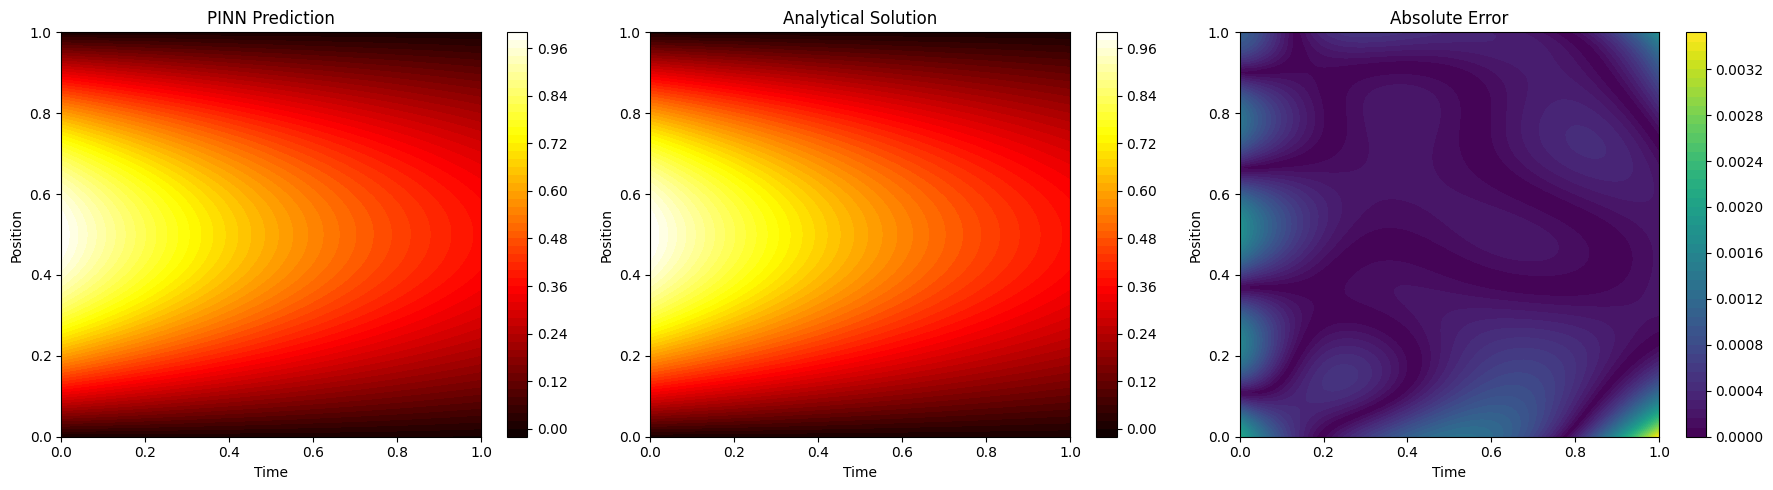

In [19]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# PINN prediction
im1 = axes[0].contourf(
    T.cpu().numpy(),
    X.cpu().numpy(),
    U_pred,
    levels=50,
    cmap="hot"
)

axes[0].set_title("PINN Prediction")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Position")

plt.colorbar(im1, ax=axes[0])


# Analytical solution
im2 = axes[1].contourf(
    T.cpu().numpy(),
    X.cpu().numpy(),
    U_exact,
    levels=50,
    cmap="hot"
)

axes[1].set_title("Analytical Solution")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Position")

plt.colorbar(im2, ax=axes[1])


# Absolute error
im3 = axes[2].contourf(
    T.cpu().numpy(),
    X.cpu().numpy(),
    U_error,
    levels=50,
    cmap="viridis"
)

axes[2].set_title("Absolute Error")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Position")

plt.colorbar(im3, ax=axes[2])


plt.tight_layout()
plt.show()

# Evaluating Model Performance

The accuracy of the PINN is evaluated by comparing its predictions with the analytical solution.

Let:

- $u_i$ represent the exact temperature.
- $\hat{u}_i$ represent the predicted temperature.
- $N$ represent the total number of evaluation points.

The following metrics are used.

### 1. Mean Squared Error (MSE)

MSE measures the average squared difference between the predicted and exact values.

$$
MSE=
\frac{1}{N}
\sum_{i=1}^{N}
(u_i-\hat{u}_i)^2
$$

### 2. Root Mean Squared Error (RMSE)

RMSE is the square root of MSE and is expressed in the same units as the temperature.

$$
RMSE=\sqrt{MSE}
$$

### 3. Relative $L_2$ Error

Relative $L_2$ error measures the overall prediction error relative to the magnitude of the exact solution.

$$
L_2^{\text{relative}}=
\frac{
\sqrt{\sum_{i=1}^{N}(u_i-\hat{u}_i)^2}
}{
\sqrt{\sum_{i=1}^{N}u_i^2}
}
$$

### 4. Maximum Absolute Error

This metric identifies the largest absolute difference between the predicted and exact values.

$$
E_{\max}=
\max_{1\leq i\leq N}
|u_i-\hat{u}_i|
$$

Lower values of these metrics indicate closer agreement between the PINN predictions and the analytical solution.

In [20]:
mse = np.mean((U_pred - U_exact) ** 2)

rmse = np.sqrt(mse)

relative_l2 = (
    np.linalg.norm(U_pred - U_exact)
    / np.linalg.norm(U_exact)
)

max_error = np.max(U_error)


print(f"MSE: {mse:.8e}")

print(f"RMSE: {rmse:.8e}")

print(f"Relative L2 Error: {relative_l2:.8e}")

print(f"Maximum Absolute Error: {max_error:.8e}")

MSE: 2.10085446e-07
RMSE: 4.58350783e-04
Relative L2 Error: 9.84843005e-04
Maximum Absolute Error: 3.50411981e-03


# Results and Discussion

After training, the PINN predictions are compared with the analytical solution of the one-dimensional heat equation.

The comparison is performed using visualizations and numerical evaluation metrics.

The following aspects are examined:

- Whether the predicted temperature distribution follows the expected diffusion behavior.
- Whether the initial temperature distribution is reproduced accurately.
- Whether the boundary temperatures remain close to zero.
- Whether the PINN temperature distribution agrees with the analytical solution.
- How the numerical error changes across the evaluation domain.

The evaluation metrics provide quantitative information about prediction accuracy, while the plots help identify differences in the spatial and temporal behavior.

The actual performance should be discussed using the values and plots obtained from the completed training run.

A low training loss does not automatically guarantee a low error across the entire domain, so comparison with the analytical solution is important.

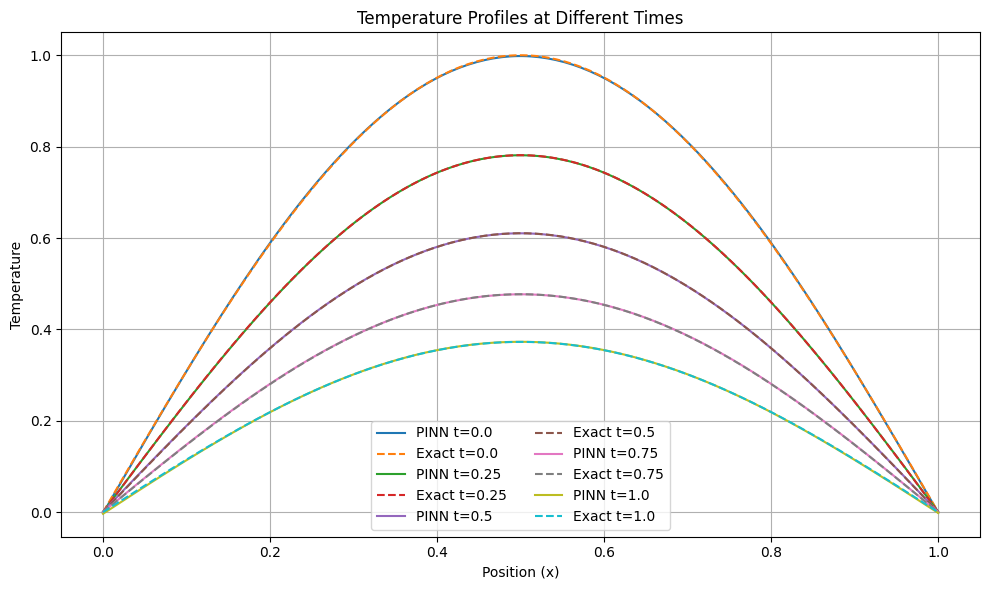

In [21]:
time_values = [0.0, 0.25, 0.5, 0.75, 1.0]

x_plot = torch.linspace(
    0, 1, 200, device=device
).reshape(-1, 1)

plt.figure(figsize=(10, 6))

for time_value in time_values:

    t_plot = torch.full_like(
        x_plot,
        time_value
    )

    with torch.no_grad():

        prediction = model(x_plot, t_plot)

        exact = analytical_solution(
            x_plot, t_plot
        )

    plt.plot(
        x_plot.cpu().numpy(),
        prediction.cpu().numpy(),
        label=f"PINN t={time_value}"
    )

    plt.plot(
        x_plot.cpu().numpy(),
        exact.cpu().numpy(),
        "--",
        label=f"Exact t={time_value}"
    )

plt.xlabel("Position (x)")
plt.ylabel("Temperature")

plt.title("Temperature Profiles at Different Times")

plt.legend(ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
torch.save(
    model.state_dict(),
    "pinn_heat_equation.pth"
)

print("Model saved successfully!")

Model saved successfully!


# Conclusion

This project demonstrates the application of a Physics-Informed Neural Network to solve the one-dimensional heat equation.

The neural network learns an approximate temperature distribution by minimizing the governing PDE residual and satisfying the initial and boundary conditions.

The PINN predictions are compared with the analytical solution using numerical metrics and visualizations.

The project provides an introduction to combining deep learning, automatic differentiation, and mathematical physics to solve scientific problems.